IMPORT LIBARIRIES 

In [1]:
# 🛠️ Advanced imports for production ML

# Suppress warnings for cleaner outputs
import warnings
warnings.filterwarnings('ignore')

# 🔧 Core Python libraries
import numpy as np           # Efficient numerical computations
import pandas as pd          # Data manipulation and analysis
import matplotlib.pyplot as plt  # Basic plotting
import seaborn as sns        # Advanced visualization
from scipy import stats      # Statistical functions
import joblib               # Save/load large models and preprocessing objects
import json                 # Handle JSON configs and outputs
from datetime import datetime  # Timestamping for logs
import os                   # File system operations
import time                 # Time tracking for experiments

# 🧰 Sklearn libraries - expanded for advanced ML workflows
from sklearn.datasets import fetch_california_housing  # Real-world dataset
from sklearn.model_selection import (
    train_test_split,     # Split data into train/test sets
    cross_val_score,      # Cross-validation scoring
    GridSearchCV,         # Hyperparameter tuning (grid search)
    RandomizedSearchCV    # Hyperparameter tuning (randomized search)
)
from sklearn.preprocessing import (
    StandardScaler,       # Feature scaling (zero-mean, unit variance)
    RobustScaler,         # Scaling robust to outliers
    PolynomialFeatures    # Generate polynomial features for non-linear relationships
)
from sklearn.pipeline import Pipeline, FeatureUnion  # Build modular pipelines
from sklearn.compose import ColumnTransformer         # Apply different preprocessing to columns
from sklearn.feature_selection import (
    SelectKBest,          # Univariate feature selection
    f_regression,         # Scoring function for regression
    RFE                   # Recursive feature elimination
)
from sklearn.linear_model import (
    LinearRegression,     # Baseline regression
    Ridge,                # L2-regularized regression
    Lasso,                # L1-regularized regression
    ElasticNet            # Combination of L1 and L2 regularization
)
from sklearn.ensemble import (
    RandomForestRegressor,       # Ensemble of decision trees
    GradientBoostingRegressor,   # Boosted trees for regression
    VotingRegressor              # Combine multiple regressors
)
from sklearn.svm import SVR               # Support Vector Regression
from sklearn.metrics import (
    mean_squared_error,  # Regression metric
    r2_score,            # Regression metric
    mean_absolute_error  # Regression metric
)
from sklearn.inspection import (
    permutation_importance,       # Feature importance
    PartialDependenceDisplay      # Partial dependence plots
)

# 🧪 Advanced model tracking with MLflow
import mlflow                  # Experiment tracking
import mlflow.sklearn          # Log sklearn models
from mlflow.models.signature import infer_signature  # Auto-capture input/output schema for reproducible deployment


In [2]:
df=pd.read_csv("insurance.csv")

In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
df.shape

(1338, 7)

In [5]:
 #Basic statistics
print("=" * 70)
print("📊 DATASET STATISTICS")
print("=" * 70)
print(df.describe())


📊 DATASET STATISTICS
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.000000  16639.912515
max      64.000000    53.130000     5.000000  63770.428010


#MISSING VALUE

In [6]:
# Missing values check
print("\n" + "=" * 70)
print("🔍 MISSING VALUES CHECK")
print("=" * 70)
print(df.isnull().sum())



🔍 MISSING VALUES CHECK
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


UNDERSTANDING DATA DISTRBUTION
Before building the models ,we examine how the numerical features are distrbuted

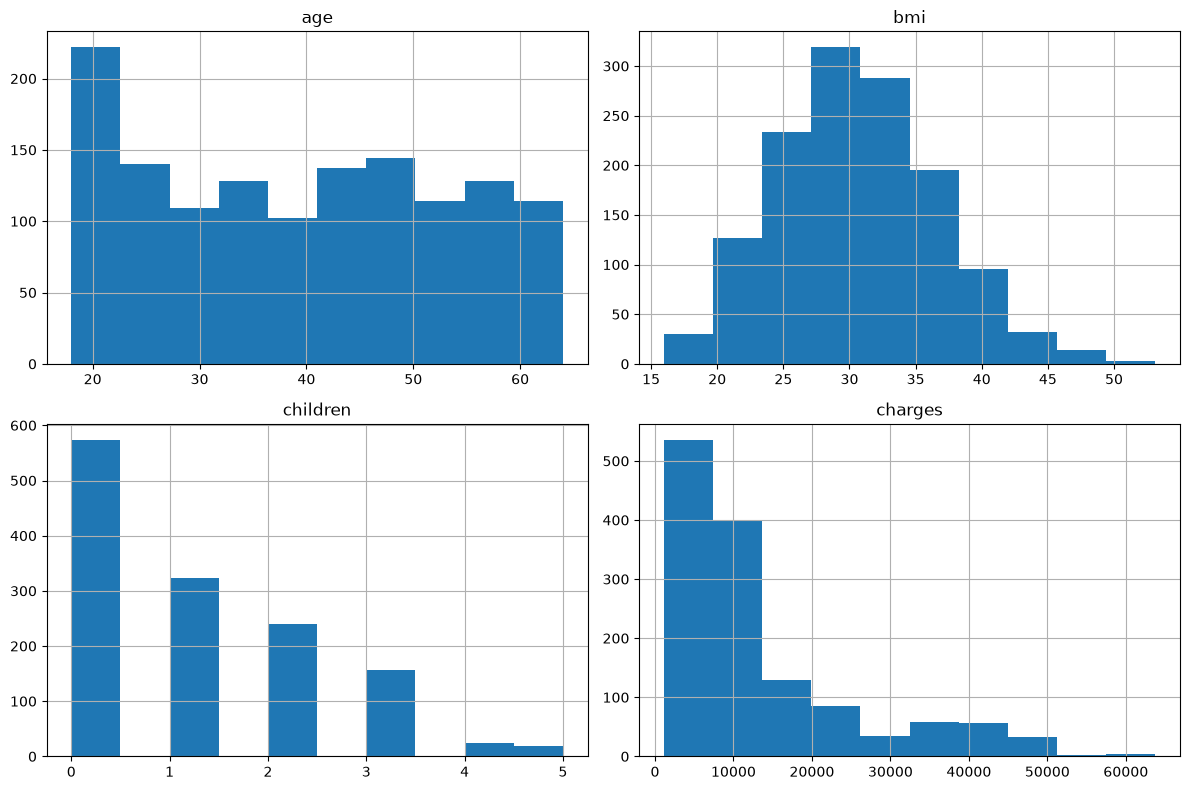

In [7]:
df.hist(figsize=(12,8))
plt.tight_layout()
plt.show()

#COLLERATION MATRIX
Analyze relationship between numerical features and the target variable

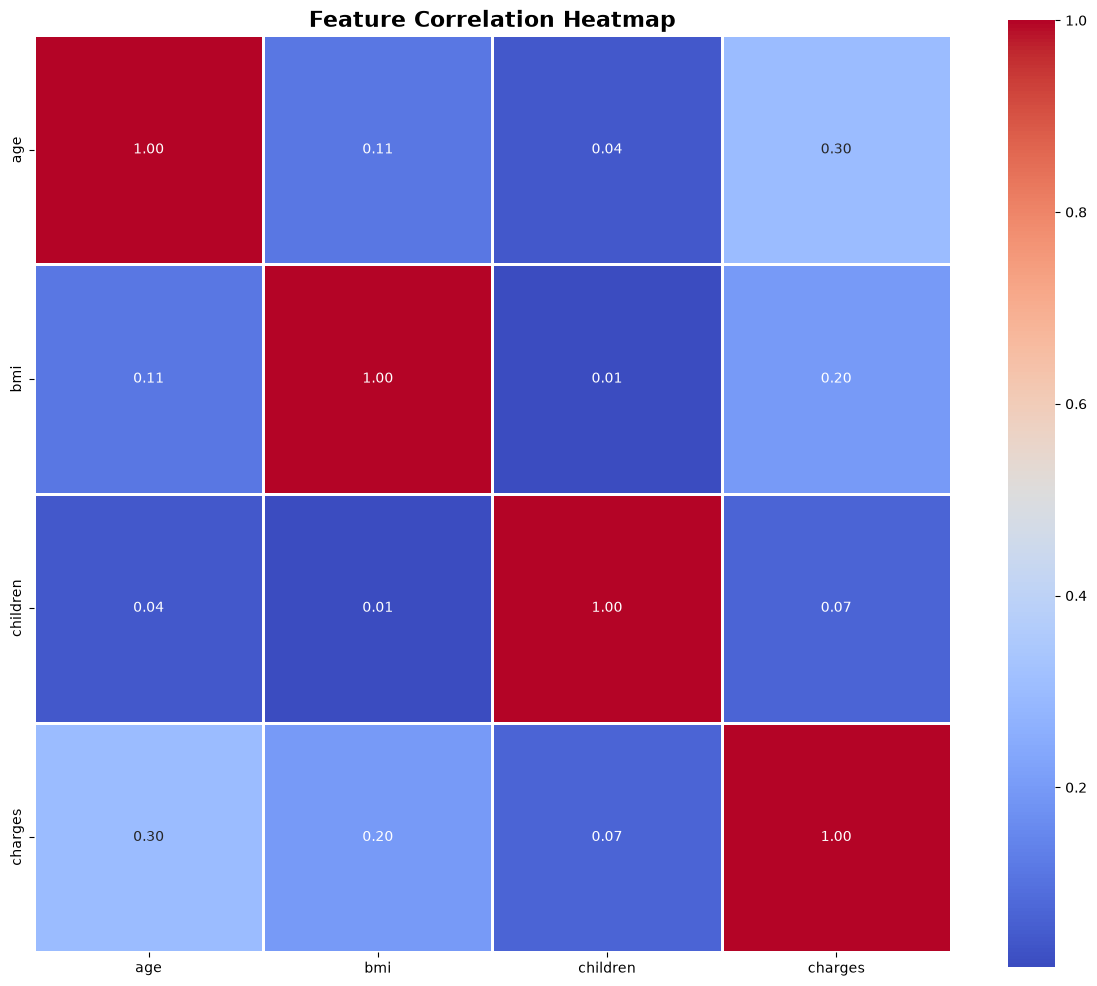


📊 FEATURES RANKED BY CORRELATION WITH CHARGES
age             0.2990
bmi             0.1983
children        0.0680


In [8]:
# Correlation matrix
correlation_matrix = df.corr(numeric_only=True)

# Plot correlation heatmap
plt.figure(figsize=(12, 10))

sns.heatmap(
    correlation_matrix,
    square=True,
    linewidths=1,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title(
    "Feature Correlation Heatmap",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# Feature importance ranking by correlation with charges
print("\n" + "=" * 70)
print("📊 FEATURES RANKED BY CORRELATION WITH CHARGES")
print("=" * 70)

correlations = (
    correlation_matrix["charges"]
    .drop("charges")
    .sort_values(ascending=False)
)

for feature, corr in correlations.items():
    print(f"{feature:<15} {corr:.4f}")

DETECTING OUTLIERS
Identify potential outliers using boxplot


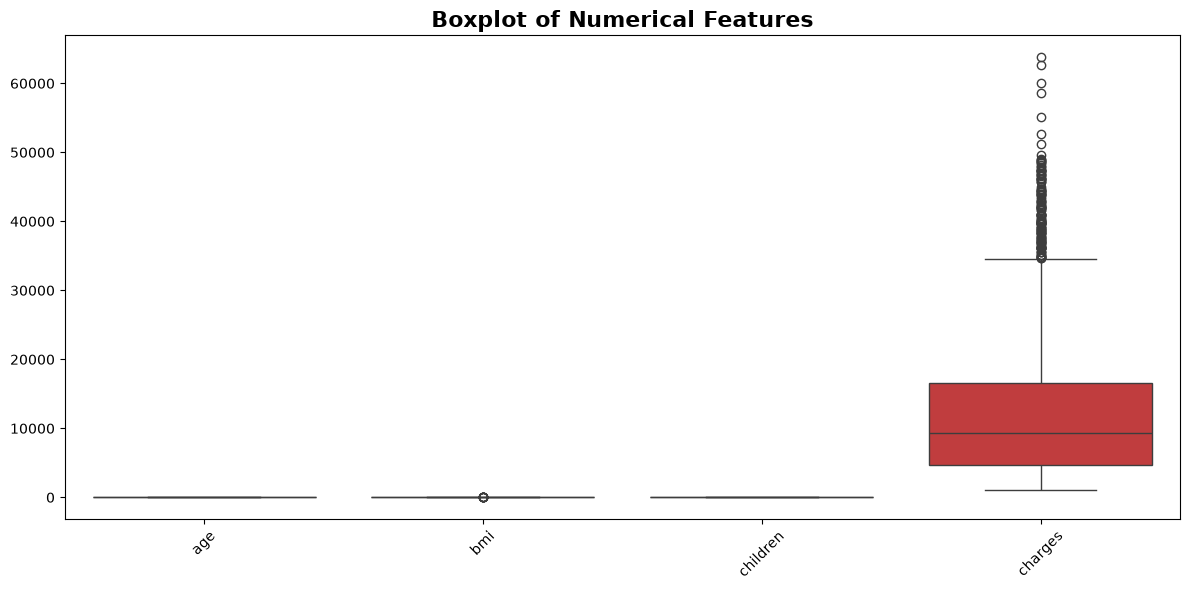

In [9]:
#Boxplot for numerical features
plt.figure(figsize=(12, 6))

sns.boxplot(data=df.select_dtypes(include=np.number))

plt.title("Boxplot of Numerical Features", fontsize=16, fontweight="bold")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [ ]:
#IQR METHOD
def get_univariate_outliers(df, numeric_cols):
    outliers_summary = []

    for col in numeric_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Detecting Outlier rows
        outliers_count = df[(df[col] < lower_bound) | (df[col] > upper_bound)].shape[
            0
        ]
        percentage = (outliers_count / len(df)) * 100

        outliers_summary.append({
            "Column": col,
            "Lower Bound": round(lower_bound, 2),
            "Upper Bound": round(upper_bound, 2),
            "Outliers Count": outliers_count,
            "Percentage (%)": round(percentage, 2),
        })

    return pd.DataFrame(outliers_summary)


#Apply function on numeric coloumns

num_cols = ["age", "bmi", "children", "charges"]
univariate_report = get_univariate_outliers(df, num_cols)
display(univariate_report)

,Column,Lower Bound,Upper Bound,Outliers Count,Percentage (%)
0,age,-9.00,87.00,0,0.00
1,bmi,13.70,47.29,9,0.67
2,children,-3.00,5.00,0,0.00
3,charges,-13109.15,34489.35,139,10.39


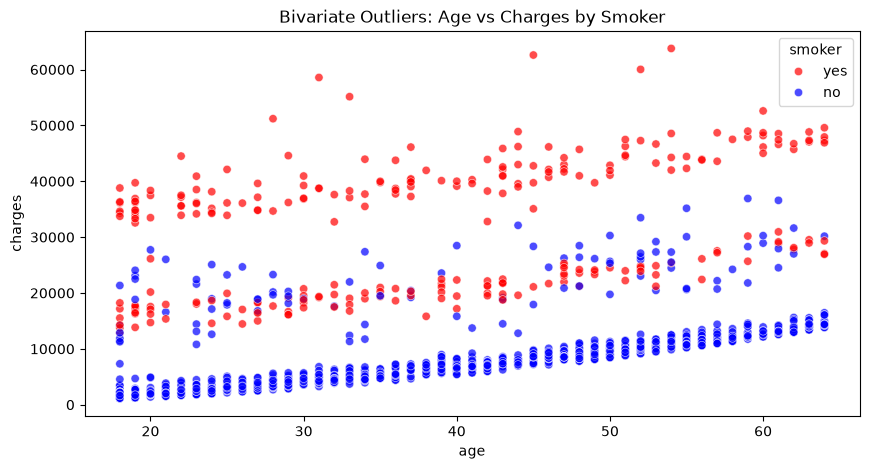

(Multivariate Outliers): 61


,age,sex,bmi,children,smoker,region,charges
3,33,male,22.705,0,no,northwest,21984.47061
9,60,female,25.840,0,no,northwest,28923.13692
45,55,male,37.300,0,no,southwest,20630.28351
62,64,male,24.700,1,no,northwest,30166.61817
102,18,female,30.115,0,no,northeast,21344.84670


In [ ]:
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df,
    x="age",
    y="charges",
    hue="smoker",
    palette={"yes": "red", "no": "blue"},
    alpha=0.7,
)
plt.title("Bivariate Outliers: Age vs Charges by Smoker")
plt.show()

# 2. Extract anomalous cases (patient is a non-smoker and the cost is greater than 20000)
non_smoker_high_cost = df[(df["smoker"] == "no") & (df["charges"] > 20000)]
print(
    f"(Multivariate Outliers): {len(non_smoker_high_cost)}"
)
display(non_smoker_high_cost.head())

HANDLING OUTLIERS

In [ ]:
df_clean = df.copy()

# ---------------------------------------------------------
# 1. Handling skewness in the target variable
# Best solution : Log transformation instead of deletion 
# ---------------------------------------------------------
df_clean["charges_log"] = np.log1p(df_clean["charges"])

# ---------------------------------------------------------
# 2. Handling outliers using BMI
# الحل الأفضل: Capping / Winsorization (تقييد القيم العلوية)
# ---------------------------------------------------------
Q1_bmi = df_clean["bmi"].quantile(0.25)
Q3_bmi = df_clean["bmi"].quantile(0.75)
IQR_bmi = Q3_bmi - Q1_bmi

upper_bound_bmi = Q3_bmi + 1.5 * IQR_bmi
lower_bound_bmi = Q1_bmi - 1.5 * IQR_bmi

# Clip values to be within acceptable bounds
df_clean["bmi"] = np.clip(df_clean["bmi"], lower_bound_bmi, upper_bound_bmi)

# ---------------------------------------------------------
# Handling(Multivariate Outliers)
# الحل الأفضل: Feature Engineering لتمييز هذه الحالات للنموذج
# ---------------------------------------------------------
# Create high BMI obesity feature 
df_clean["high_bmi_obese"] = (df_clean["bmi"] >= 30).astype(int)
df_clean["smoker_bmi_interaction"] = (
    df_clean["smoker"].map({"yes": 1, "no": 0}) * df_clean["bmi"]
)

DATA TYPE

In [13]:
#Data types
print("\n" + "=" * 70)
print("📋 DATA TYPES")
print("=" * 70)
print(df.dtypes)


📋 DATA TYPES
age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object


ENCODING 
Convert categorical variables into numerical representation


In [ ]:
from sklearn.preprocessing import OneHotEncoder
#Dropping duplicate coloumn from data
df_clean = df_clean.drop(columns=["Region"], errors="ignore")

# 2. Sepeart independent variables x from target variable y
X = df_clean.drop(
    columns=["charges", "charges_log", "is_multivariate_outlier"],
    errors="ignore",
)
y = df_clean["charges"]

# 3. Automitically identifying categorical and numeric coloumns 
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

# 4. Building ColumnTransformer for data prepocessing 
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numeric_cols,
        ),  # Keep numeric coloumns as is 
        (
            "cat",
            OneHotEncoder(drop="first", sparse_output=False),
            categorical_cols,
        ),  # Encode categorical coloumns 
    ]
)

# 5. Apply encoding on X
X_encoded = preprocessor.fit_transform(X)

# Print to verify the operation was sucessful
print("📋 Categorical coloumns", categorical_cols)
print( "Numeric Coloumns:", numeric_cols)
print( "(Shape):", X_encoded.shape)

📋 الأعمدة النصية المشفرة: ['sex', 'smoker', 'region']
🔢 الأعمدة الرقمية: ['age', 'bmi', 'children', 'high_bmi_obese', 'smoker_bmi_interaction']
📐 أبعاد المصفوفة بعد التشفير (Shape): (1338, 10)


SPLIT DATA TO X & Y
Seperate input features (X) from the target variable (y)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
#SPLIT DATA USING ENCODED VARIABLE
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

# 2. Apply Roboust scaler on Encoded Date
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

SCALLING


In [26]:
# Initialize scaler
scaler = StandardScaler()

# Fit on training data only (prevent data leakage)
X_train_scaled = scaler.fit_transform(X_train) 
X_test_scaled = scaler.transform(X_test)

print("=" * 70)
print("⚖️ FEATURE SCALING APPLIED")
print("=" * 70)
print("\nBefore scaling (first sample):")
print(X_train[0])
print("\nAfter scaling (first sample):")
print(X_train_scaled[0])

⚖️ FEATURE SCALING APPLIED

Before scaling (first sample):
[46.   19.95  2.    0.    0.    0.    0.    1.    0.    0.  ]

After scaling (first sample):
[ 0.47222651 -1.76465198  0.73433626 -1.04395582 -0.4960015  -1.0246016
 -0.50874702  1.78316783 -0.59966106 -0.5723141 ]


In [27]:
import joblib
joblib.dump(scaler,"scaler.pkl")

['scaler.pkl']

BEFORE SCALING VS AFTER SCALING

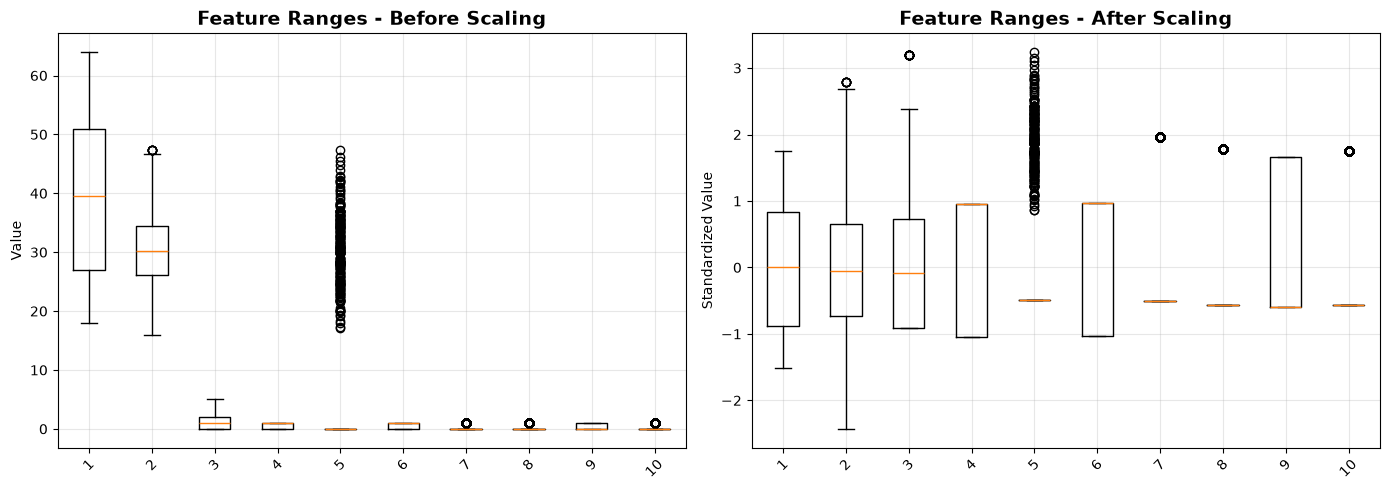

In [17]:
# Visualization: Before vs After
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Before scaling
axes[0].boxplot(X_train)
axes[0].set_title('Feature Ranges - Before Scaling', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Value')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, alpha=0.3)

# After scaling
axes[1].boxplot(X_train_scaled)
axes[1].set_title('Feature Ranges - After Scaling', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Standardized Value')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

TRAINING & EVALUATION
Train models and evaluate them using MAE, RMSE, R2

In [18]:
def train_and_evaluate(model, X_train, y_train, X_val, y_val):
    """Train model and compute basic metrics on train and validation sets."""
    start_time = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start_time

    y_train_pred = model.predict(X_train)
    y_val_pred = model.predict(X_val)

    metrics = {
        "train_rmse": np.sqrt(mean_squared_error(y_train, y_train_pred)),
        "val_rmse": np.sqrt(mean_squared_error(y_val, y_val_pred)),
        "train_r2": r2_score(y_train, y_train_pred),
        "val_r2": r2_score(y_val, y_val_pred),
        "train_mae": mean_absolute_error(y_train, y_train_pred),
        "val_mae": mean_absolute_error(y_val, y_val_pred),
        "training_time": training_time,
        "overfitting_gap": r2_score(y_train, y_train_pred) - r2_score(y_val, y_val_pred) # EARLY DETECTION FOR OVERFITTING
    }

    return metrics, model

MODEL SELECTION
Compare models and select the best performing candidate

=== جدول مقارنة أداء النماذج ===
                   Model  R2 Score           MSE
0       Voting Regressor  0.882470  1.824634e+07
1      Gradient Boosting  0.879124  1.876591e+07
2  Polynomial Regression  0.874547  1.947648e+07
3                  Ridge  0.869037  2.033178e+07
4                  Lasso  0.868936  2.034756e+07
5      Linear Regression  0.868904  2.035243e+07
6          Random Forest  0.864104  2.109761e+07
7                    SVR -0.068711  1.659160e+08


Text(0, 0.5, '')

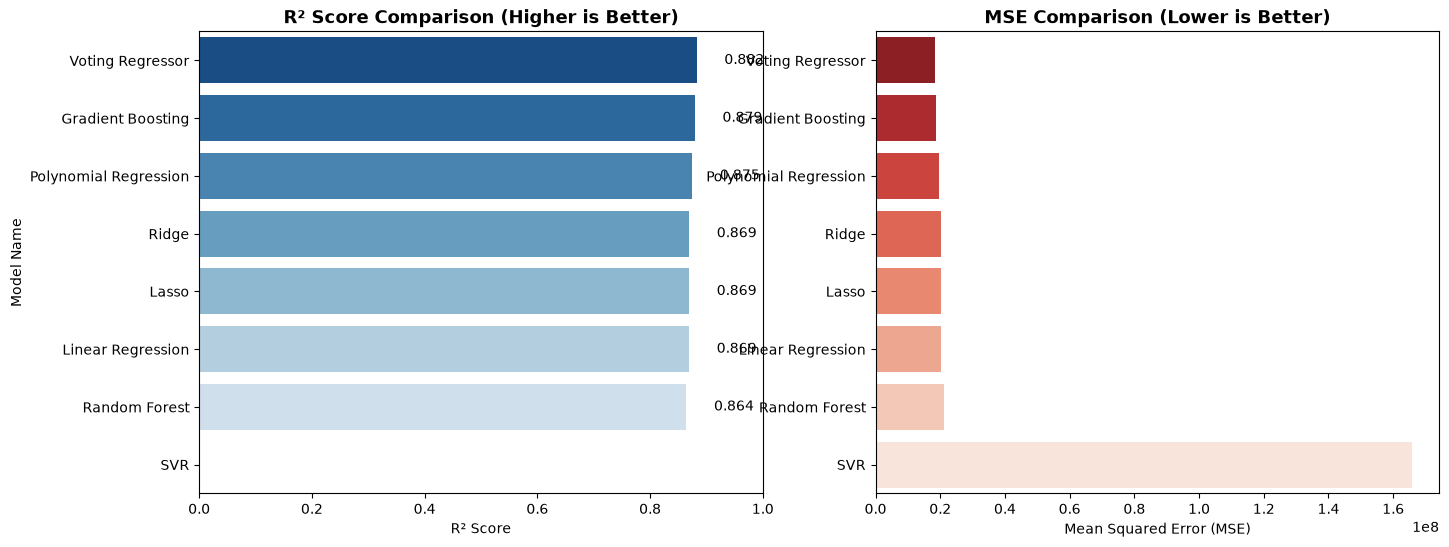

In [ ]:
from sklearn.ensemble import (
    GradientBoostingRegressor,
    RandomForestRegressor,
    VotingRegressor,
)
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.svm import SVR

# 1. Setting up and defining 8 models
rf = RandomForestRegressor(random_state=42)
gb = GradientBoostingRegressor(random_state=42)
ridge = Ridge()

models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": ridge,
    "Polynomial Regression": make_pipeline(
        PolynomialFeatures(degree=2), LinearRegression()
    ),
    "Random Forest": rf,
    "Gradient Boosting": gb,
    "SVR": SVR(),
    "Voting Regressor": VotingRegressor(
        estimators=[("rf", rf), ("gb", gb), ("ridge", ridge)]
    ),
}

# 2. Model training loop and calculating MSE and R2
results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)

    results.append({"Model": name, "R2 Score": r2, "MSE": mse})

# Convert result to DataFrame and sort them from best to bottom
results_df = pd.DataFrame(results).sort_values(
    by="R2 Score", ascending=False
).reset_index(drop=True)

# 3. printing the table
print("=== MODEL PERFORMANCE COMPARSION TABLE===")
print(results_df)

# 4. Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
#First plot R² Score 

sns.barplot(
    data=results_df, x="R2 Score", y="Model", ax=axes[0], palette="Blues_r"
)
axes[0].set_title(
    "R² Score Comparison (Higher is Better)", fontsize=13, fontweight="bold"
)
#Set the range between 0 & 1
axes[0].set_xlabel("R² Score")
axes[0].set_ylabel("Model Name")
axes[0].set_xlim(0, 1)  



#Add values on the R2 bar
for p in axes[0].patches:
    width = p.get_width()
    axes[0].annotate(
        f"{width:.3f}",
        (width, p.get_y() + p.get_height() / 2.0),
        ha="left",
        va="center",
        xytext=(20, 0),
        textcoords="offset points",
    )

# Second plot MSE
sns.barplot(
    data=results_df, x="MSE", y="Model", ax=axes[1], palette="Reds_r"
)
axes[1].set_title(
    "MSE Comparison (Lower is Better)", fontsize=13, fontweight="bold"
)
axes[1].set_xlabel("Mean Squared Error (MSE)")
axes[1].set_ylabel("")

HYPERPARMETER TUNING
Optimize model parameters to improve performance 

In [20]:
from sklearn.ensemble import GradientBoostingRegressor, VotingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

# =========================================================
# 1. Hyperparameter Tuning: Gradient Boosting Regressor
# =========================================================
gb_param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [3, 4, 5],
    "subsample": [0.8, 1.0],
}

grid_gb = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=gb_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
)
grid_gb.fit(X_train_scaled, y_train)
best_gb = grid_gb.best_estimator_

# =========================================================
# 2. Hyperparameter Tuning: Polynomial Regression
# =========================================================
poly_pipeline = Pipeline([
    ("poly", PolynomialFeatures()),
    ("regressor", LinearRegression()),
])

poly_param_grid = {
    "poly__degree": [2, 3],
    "poly__include_bias": [False],
}

grid_poly = GridSearchCV(
    estimator=poly_pipeline,
    param_grid=poly_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
)
grid_poly.fit(X_train_scaled, y_train)
best_poly = grid_poly.best_estimator_

# =========================================================
# 3. Hyperparameter Tuning: Ridge Regression
# =========================================================
ridge_param_grid = {
    "alpha": [0.01, 0.1, 1.0, 10.0, 100.0],
    "solver": ["auto", "saga", "lsqr"],
}

grid_ridge = GridSearchCV(
    estimator=Ridge(random_state=42),
    param_grid=ridge_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
)
grid_ridge.fit(X_train_scaled, y_train)
best_ridge = grid_ridge.best_estimator_

# =========================================================
# 4. Construct & Train Final Voting Regressor Ensemble
# =========================================================
voting_model = VotingRegressor(
    estimators=[
        ("gb", best_gb),
        ("poly", best_poly),
        ("ridge", best_ridge),
    ]
)
voting_model.fit(X_train_scaled, y_train)

# Calculate 5-Fold Cross-Validation R² for VotingRegressor
voting_cv_r2 = cross_val_score(
    voting_model, X_train_scaled, y_train, cv=5, scoring="r2"
).mean()

# =========================================================
# 5. Top 3 Models Comparison Summary
# =========================================================
top_3_summary = pd.DataFrame({
    "Model": [
        "Voting Regressor (Ensemble)",
        "Gradient Boosting (Tuned)",
        "Polynomial Regression (Tuned)",
    ],
    "CV R² Score": [
        voting_cv_r2,
        grid_gb.best_score_,
        grid_poly.best_score_,
    ],
})

# Sort models by performance
top_3_summary = top_3_summary.sort_values(
    by="CV R² Score", ascending=False
).reset_index(drop=True)

print("=== Top 3 Final Models Comparison ===")
print(top_3_summary.to_string(index=False))

=== Top 3 Final Models Comparison ===
                        Model  CV R² Score
Polynomial Regression (Tuned)     0.855509
  Voting Regressor (Ensemble)     0.854829
    Gradient Boosting (Tuned)     0.848057


CROSS VALIDATION
Evaluate model performance across multiple data folds

In [21]:
#1. Define 5-Fold Cross-Validation strategy
from sklearn.model_selection import KFold, cross_val_score
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 2. Compute R² score across all 5 folds
cv_r2_scores = cross_val_score(
voting_model, X_train_scaled, y_train, cv=kf, scoring="r2")

# 3. Compute RMSE score across all 5 folds
cv_mse_scores = cross_val_score(
    voting_model,
    X_train_scaled,
    y_train,
    cv=kf,
    scoring="neg_mean_squared_error",
)
cv_rmse_scores = np.sqrt(-cv_mse_scores)

# 4. Print cross-validation performance metrics
print("=== 5-Fold Cross-Validation Results ===")
print(f"R² Scores per fold:  {np.round(cv_r2_scores, 4)}")
print(
    f"Mean R² Score:      {cv_r2_scores.mean():.4f} (+/-"
    f" {cv_r2_scores.std():.4f})\n"
)

=== 5-Fold Cross-Validation Results ===
R² Scores per fold:  [0.8304 0.8483 0.9079 0.8315 0.8838]
Mean R² Score:      0.8604 (+/- 0.0306)



SAVING THE BEST MODEL

In [22]:
import joblib

# Save the best polynomial model
joblib.dump(best_poly, "best_polynomial_model.pkl")
print("✅ Best Polynomial Regression model saved successfully!")

✅ Best Polynomial Regression model saved successfully!


FEATURE IMPORTANT ANALYSIS
Identify the features that contribute most to model performance

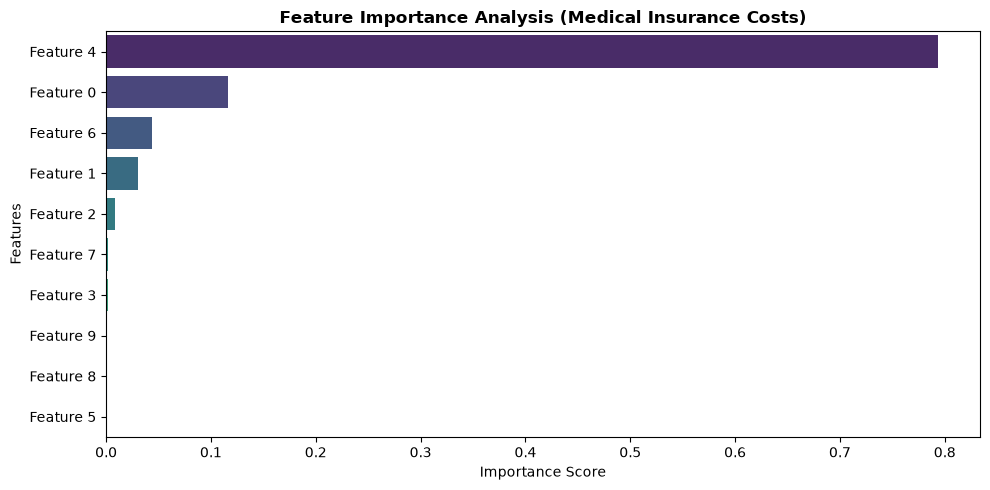

In [23]:
# Extract feature importances from the Gradient Boosting estimator inside VotingRegressor
gb_model = models["Voting Regressor"].named_estimators_["gb"]
importances = gb_model.feature_importances_

# Extract feature names from the training set
feature_names = (
    X_train_scaled.columns
    if hasattr(X_train_scaled, "columns")
    else [f"Feature {i}" for i in range(X_train_scaled.shape[1])]
)

# Create DataFrame and sort by importance
feature_imp_df = pd.DataFrame(
    {"Feature": feature_names, "Importance": importances}
).sort_values(by="Importance", ascending=False)

# Plotting
plt.figure(figsize=(10, 5))
sns.barplot(
    data=feature_imp_df, x="Importance", y="Feature", palette="viridis"
)
plt.title(
    "Feature Importance Analysis (Medical Insurance Costs)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

ML LOGGING & TRACING WITH ML FLOW 
MLflow tracks machine learning experiments , records model performance, and helps compare models

In [24]:
import joblib
import mlflow
import mlflow.sklearn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Select the best model
best_model = best_poly

# 2. Set MLflow experiment name
mlflow.set_experiment("Medical_Insurance_Final_Pipeline")

# 3. Log run details with MLflow
with mlflow.start_run(run_name="Final_Polynomial_Regression"):
  # Evaluate on test set
  y_pred = best_model.predict(X_test_scaled)

  # Compute test metrics
  r2 = r2_score(y_test, y_pred)
  mse = mean_squared_error(y_test, y_pred)
  mae = mean_absolute_error(y_test, y_pred)

  # Log hyper-parameters
  mlflow.log_param("model_type", "PolynomialRegression")
  mlflow.log_param("degree", best_poly.named_steps["poly"].degree)

  # Log evaluation metrics
  mlflow.log_metric("r2", r2)
  mlflow.log_metric("mse", mse)
  mlflow.log_metric("mae", mae)

  # Log model artifact
  mlflow.sklearn.log_model(best_model, "polynomial_model")

  print("✅ MLflow run logged successfully!")
  print(f"Test R²: {r2:.4f} | Test MAE: ${mae:.2f}")

2026/10/11 20:29:33 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet

2026/10/11 20:29:33 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably

✅ MLflow run logged successfully!
Test R²: 0.8745 | Test MAE: $2405.62


Model Prediction Range VS Actual Test Data
Compare the predicted and actual medical insurance charges using minmum and maximum

In [ ]:
print("Original charges:")
print(y.describe())

print("\nModel prediction range:")
print("Minimum:", grid_poly.predict(X_test_scaled).min())
print("Maximum:", grid_poly.predict(X_test_scaled).max())

print("\nActual test values:")
print("Minimum:", y_test.min())
print("Maximum:", y_test.max())

Original charges:
count     1338.000000
mean     13270.422265
std      12110.011237
min       1121.873900
25%       4740.287150
50%       9382.033000
75%      16639.912515
max      63770.428010
Name: charges, dtype: float64

Model prediction range:
Minimum: 835.065489799822
Maximum: 50538.22980556971

Actual test values:
Minimum: 1131.5066
Maximum: 63770.42801
